# **CVC-ClinicDB Dataset**

In [2]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


In [3]:
# Dataset Paths
dataset_path = "data/CVC-ClinicDB"
image_dir = "Original"
mask_dir = "Ground Truth"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 612
Number of training samples: 550
Number of testing samples: 62


# Unet CVC model training config

In [4]:
cfg = TrainConfig(
    # --- General ---
    model_name = "TransUNet",
    dataset_name = "CVC-ClinicDB",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 2e-4,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [5]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc
wandb: Currently logged in as: mironshoh (iv-drip-counter) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [6]:
model = create_transunet(config='base', num_classes=1, img_size=256)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-10 08:32:18 | INFO | TransUNet_model_CVC_ClinicDB_20250910_083218 | Logging to model_comparisons/logs/TransUNet_model_CVC_ClinicDB_20250910_083218.log
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


2025-09-10 08:32:19 | INFO | TransUNet_model_CVC_ClinicDB_20250910_083218 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/dvoxcen4
100%|██████████| 8/8 [00:00<00:00, 12.05it/s]
2025-09-10 08:32:33 | INFO | TransUNet_model_CVC_ClinicDB_20250910_083218 | Epoch 001/100 | Train: 0.942955 | Val: 0.927450 | LR: 0.000200 | 13.64s | Val Dice: 0.3120 IoU: 0.2055 F1: 0.3769
2025-09-10 08:32:33 | INFO | TransUNet_model_CVC_ClinicDB_20250910_083218 | Saved best: model_comparisons/models/best_TransUNet_model_CVC_ClinicDB_20250910_083218.pth (val=0.927450)
100%|██████████| 8/8 [00:00<00:00, 12.29it/s]
2025-09-10 08:32:47 | INFO | TransUNet_model_CVC_ClinicDB_20250910_083218 | Epoch 002/100 | Train: 0.801639 | Val: 0.877197 | LR: 0.000200 | 13.13s | Val Dice: 0.3066 IoU: 0.2154 F1: 0.4362
2025-09-10 08:32:48 | INFO | TransUNet_model_CVC_ClinicDB_20250910_083218 | Saved best: model_comparisons/models/best_TransUNet_model_CVC_ClinicDB_20250910_083218.pth (val=0.877197)
100%|███████

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,█▇▆▆▆▄▄▃▃▃▃▃▃▃▃▃▃▃▄▃▃▂▃▃▂▁▃▂▂▂▂▂▂▂▂▁▂▂▂▂
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▁▂▂▃▃▅▆▆▆▆▆▆▆▆▆▆▅▆▆▆▆▆▇▇█▇▇▇▇▆▇▇▇█▇█▇▇▇▇
epoch_seconds,▄▁▇▃▃▂█▂▁▁▂▂▄▁▁▁▃▃▄▅▂▁▄▃▂▂▃▂▂▂▂▂▃▂▂▂▃▂▂▃
lr,███████████████▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▄▂▂▂▂▂▂▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▂▃▃▃▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███████████████████
train/f1,▁▂▃▃▃▄▄▅▅▅▆▆▆▆▆▆▇▇▇▇████████████████████
train/iou,▁▁▂▂▂▃▄▄▄▄▅▅▅▅▆▆▇▇▇▇▇▇▇▇▇▇▇▇████████████
+11,...


{'best_val_loss': 0.3042692709714174,
 'epochs_ran': 52,
 'best_model_path': 'model_comparisons/models/best_TransUNet_model_CVC_ClinicDB_20250910_083218.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_TransUNet_CVC_ClinicDB_20250910_083218.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/dvoxcen4',
 'log_path': 'model_comparisons/logs/TransUNet_model_CVC_ClinicDB_20250910_083218.log'}

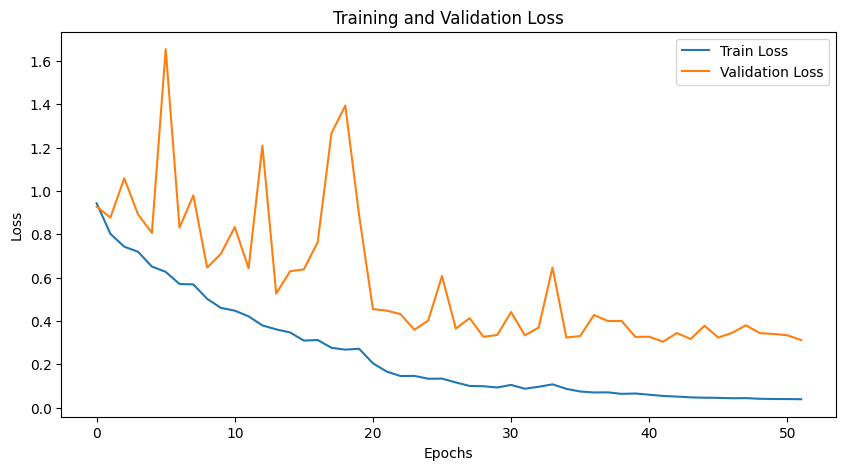

In [7]:
trainer.plot_losses()

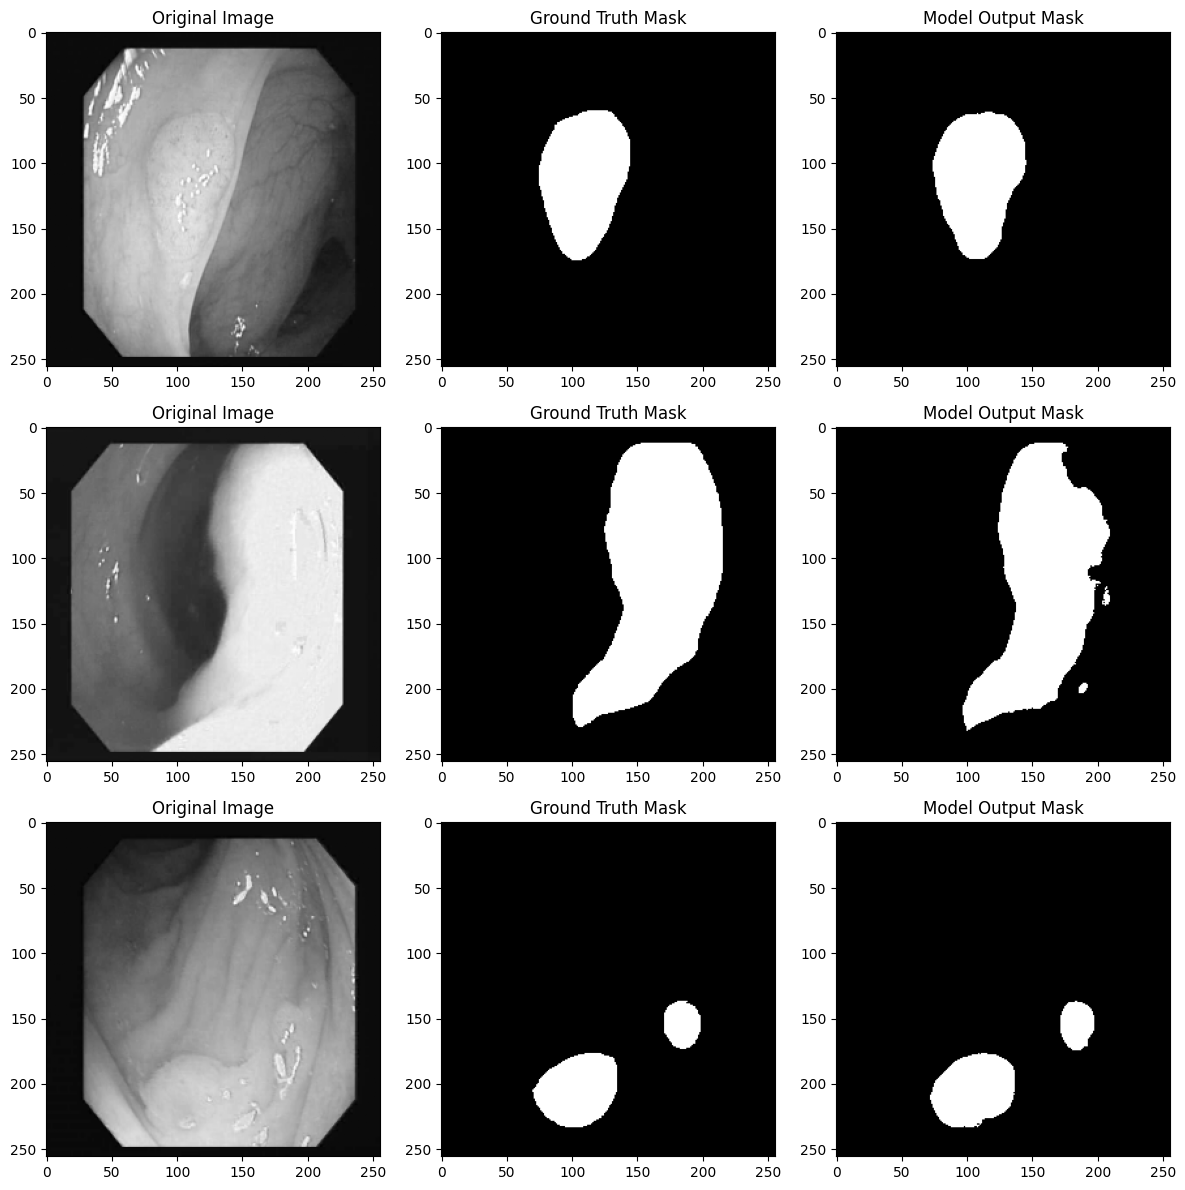

In [8]:
trainer.visualize_output_samples()

In [9]:
trainer.validate_and_save()

100%|██████████| 8/8 [00:00<00:00, 10.04it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.3117
Average Dice Score                 : 0.8118
Average Hausdorff Distance         : 34.6269
Average IoU                        : 0.7255
Precision                          : 0.9235
Recall                             : 0.7652
F1 Score                           : 0.8369
IoU (batch avg)                    : 0.7161
Dice (batch avg)                   : 0.8289
Total Parameters                   : 89,915,841
Trainable Parameters               : 89,915,841
Average Inference Time (seconds)   : 0.039842
FPS (Frames Per Second)            : 25.10
FLOPs                              : 32,394,407,936.0
GFLOPs                             : 32.3944

Results saved to: model_comparisons/evaluation_results/TransUNet_model_CVC-ClinicDB_evaluation_results_20250910_083218.csv
Validation results saved to model_comparisons/evaluation_results/TransUNet_model_CVC-ClinicDB_evaluation_results


{'test_loss': 0.31169894337654114,
 'avg_dice_score': 0.8118159927788281,
 'avg_hd_score': 34.62694903342955,
 'avg_iou': 0.7255385630433598,
 'precision': 0.9234521951691088,
 'recall': 0.765167314640782,
 'f1': 0.8368912384012817,
 'iou_batch_avg': 0.7161043584346771,
 'dice_batch_avg': 0.8288577347993851,
 'total_params': 89915841,
 'trainable_params': 89915841,
 'avg_inference_time': 0.03984209537506103,
 'fps': 25.099081526368344,
 'flops': 32394407936.0,
 'gflops': 32.394407936}

# **Kvasir-SEG dataset**

In [2]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


In [3]:
# Dataset Paths
dataset_path = "data/Kvasir-SEG"
image_dir = "images"
mask_dir = "masks"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 1000
Number of training samples: 900
Number of testing samples: 100


# UNet Kvasir training config

In [4]:
cfg = TrainConfig(
    # --- General ---
    model_name = "TransUNet",
    dataset_name = "Kvasir-SEG",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 3e-4,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [5]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc
wandb: Currently logged in as: mironshoh (iv-drip-counter) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [6]:
model = create_transunet(config='base', num_classes=1, img_size=256)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-10 09:06:02 | INFO | TransUNet_model_Kvasir_SEG_20250910_090602 | Logging to model_comparisons/logs/TransUNet_model_Kvasir_SEG_20250910_090602.log
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


2025-09-10 09:06:03 | INFO | TransUNet_model_Kvasir_SEG_20250910_090602 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/yqnhu5yo
100%|██████████| 13/13 [00:01<00:00,  7.39it/s]
2025-09-10 09:06:24 | INFO | TransUNet_model_Kvasir_SEG_20250910_090602 | Epoch 001/100 | Train: 1.007229 | Val: 0.896030 | LR: 0.000300 | 20.83s | Val Dice: 0.4818 IoU: 0.3487 F1: 0.5151
2025-09-10 09:06:24 | INFO | TransUNet_model_Kvasir_SEG_20250910_090602 | Saved best: model_comparisons/models/best_TransUNet_model_Kvasir_SEG_20250910_090602.pth (val=0.896030)
100%|██████████| 13/13 [00:01<00:00,  8.54it/s]
2025-09-10 09:06:46 | INFO | TransUNet_model_Kvasir_SEG_20250910_090602 | Epoch 002/100 | Train: 0.870293 | Val: 0.882445 | LR: 0.000300 | 20.10s | Val Dice: 0.4394 IoU: 0.3174 F1: 0.4779
2025-09-10 09:06:46 | INFO | TransUNet_model_Kvasir_SEG_20250910_090602 | Saved best: model_comparisons/models/best_TransUNet_model_Kvasir_SEG_20250910_090602.pth (val=0.882445)
100%|██████████| 13/13

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,█▇▇▇▆▆▆▆▃▃▄▄▂▃▂▂▄▃▃▂▃▂▂▂▂▄▃▄▃▃▂▂▄▂▃▃▃▄▁▂
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▁▂▂▃▃▃▃▆▆▆▆▅▇▇▅▅▆▆▇▇▅▇▇▇▇▅▆▅▆▆▇▅▇▆▆▆▆▆█▇
epoch_seconds,▄▁▇▆▆▅▁▄█▅▅▄▃▃█▄▄▄▆▃▇▄▄▃▆▂▅▅▃▅▄▄▄▅▄▃▄▅▃▅
lr,████████████████████▄▄▄▄▄▄▄▂▂▂▂▂▂▂▂▂▂▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▂▃▃▃▄▄▄▄▄▄▄▄▅▅▆▆▆▆▆▆▆▆▆▇▇▆▆▇▇▇▇▇▇██████
train/f1,▁▂▂▂▃▃▃▄▄▃▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▅▆▇▇▇▇▇▇▇▇█████
train/iou,▁▂▂▃▃▃▃▄▃▃▃▃▄▄▅▅▅▅▅▅▆▆▆▆▆▅▆▆▆▇▇▇▇▇▇▇████
+11,...


{'best_val_loss': 0.4208518323990015,
 'epochs_ran': 52,
 'best_model_path': 'model_comparisons/models/best_TransUNet_model_Kvasir_SEG_20250910_090602.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_TransUNet_Kvasir_SEG_20250910_090602.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/yqnhu5yo',
 'log_path': 'model_comparisons/logs/TransUNet_model_Kvasir_SEG_20250910_090602.log'}

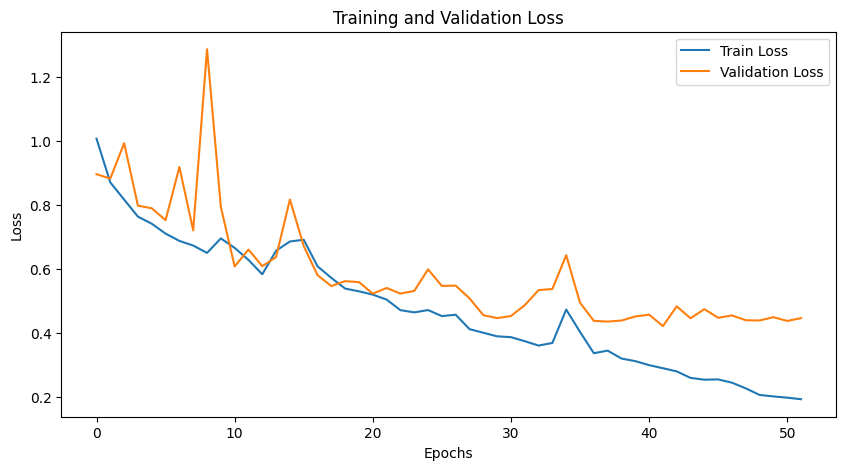

In [7]:
trainer.plot_losses()

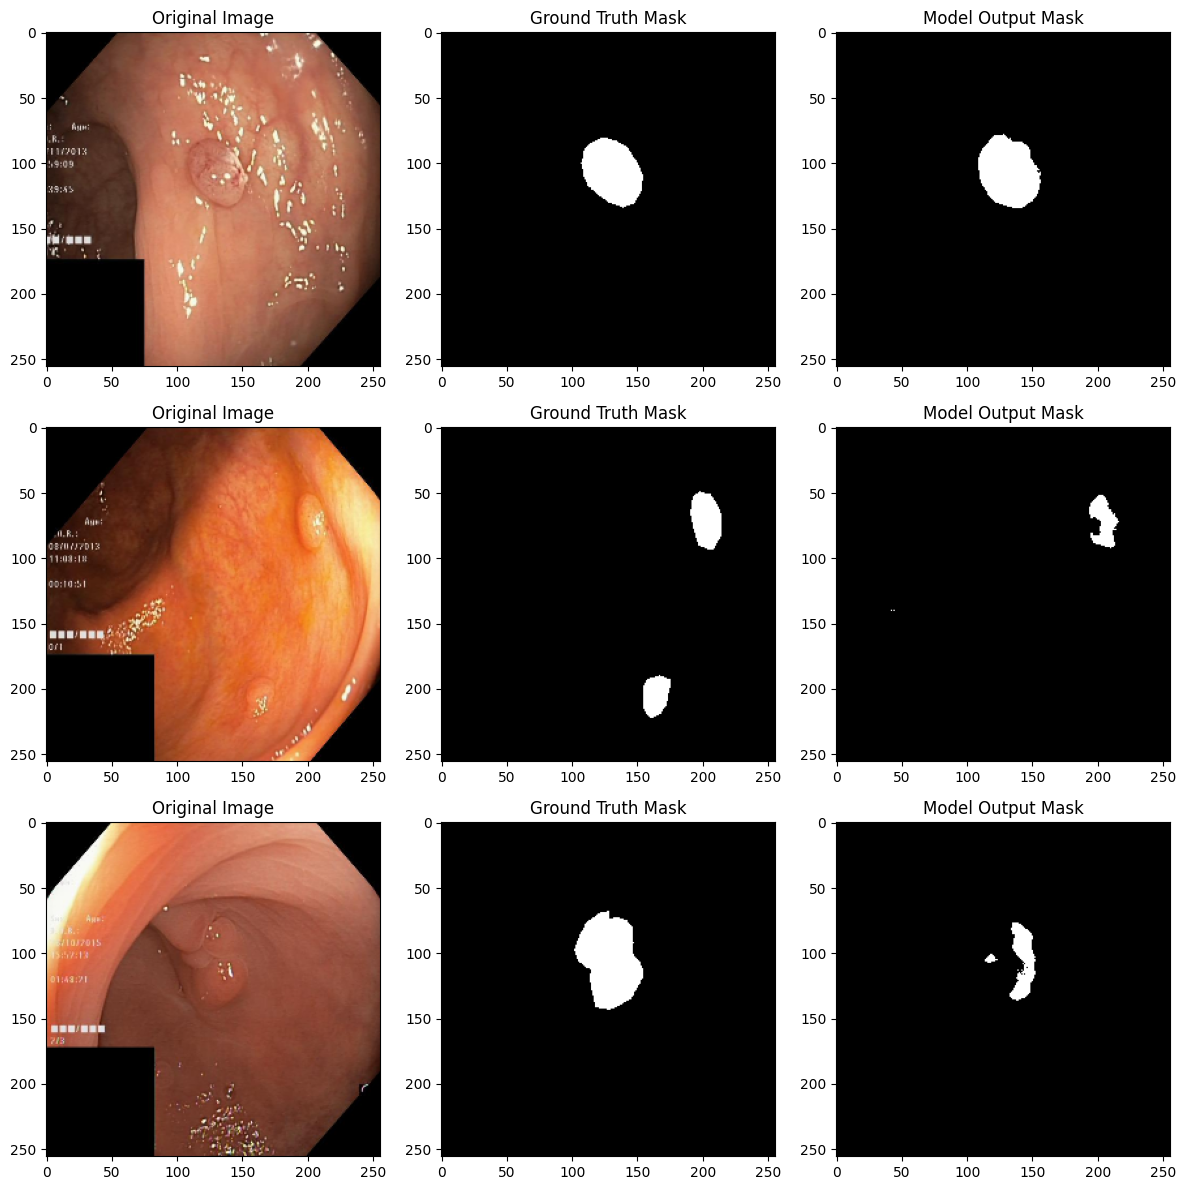

In [8]:
trainer.visualize_output_samples()

In [9]:
trainer.validate_and_save()

100%|██████████| 13/13 [00:01<00:00,  6.76it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.4458
Average Dice Score                 : 0.7781
Average Hausdorff Distance         : inf
Average IoU                        : 0.6697
Precision                          : 0.8033
Recall                             : 0.7696
F1 Score                           : 0.7861
IoU (batch avg)                    : 0.6562
Dice (batch avg)                   : 0.7888
Total Parameters                   : 89,915,841
Trainable Parameters               : 89,915,841
Average Inference Time (seconds)   : 0.039849
FPS (Frames Per Second)            : 25.09
FLOPs                              : 32,394,407,936.0
GFLOPs                             : 32.3944

Results saved to: model_comparisons/evaluation_results/TransUNet_model_Kvasir-SEG_evaluation_results_20250910_090602.csv
Validation results saved to model_comparisons/evaluation_results/TransUNet_model_Kvasir-SEG_evaluation_results


{'test_loss': 0.44584041833877563,
 'avg_dice_score': 0.7781156954179582,
 'avg_hd_score': inf,
 'avg_iou': 0.6697461967925605,
 'precision': 0.8033370797138746,
 'recall': 0.769613392543575,
 'f1': 0.7861137221788519,
 'iou_batch_avg': 0.6561937148754413,
 'dice_batch_avg': 0.7888419719842764,
 'total_params': 89915841,
 'trainable_params': 89915841,
 'avg_inference_time': 0.03984871864318848,
 'fps': 25.09490980009051,
 'flops': 32394407936.0,
 'gflops': 32.394407936}